In [2]:

import os
from typing import Literal
from dotenv import load_dotenv

from pydantic import BaseModel, Field
from langchain_openai import ChatOpenAI
from langchain_core.prompts import ChatPromptTemplate
from langgraph.graph import StateGraph, START, END

load_dotenv()


#  LLM
model = ChatOpenAI(
    model="meta/muse-glimmer-30b",
    base_url="https://integrate.api.nvidia.com/v1",
    api_key=os.getenv("NVIDIA_API_KEY"),
    temperature=0.2,
    max_tokens=500,
    reasoning_effort="low"
)


#  Pydantic structured output
class RouteDecision(BaseModel):
    category: Literal["technical", "general"] = Field(description="The category of the user's question")
    reasoning: str = Field(description="Why this category was selected")


structured_model = model.with_structured_output(RouteDecision,method="function_calling")


# 3. Prompt
decision_prompt = ChatPromptTemplate.from_messages([
    ("system", """
    Classify the user's question.

    - technical: programming, software development, databases, AI.
    - general: other questions.

    Return the result using the provided schema.
    """),
    ("human", "{question}")
])

decision_chain = decision_prompt | structured_model


#  Pydantic graph state
class AgentState(BaseModel):
    question: str
    decision: RouteDecision | None = None
    answer: str = ""


In [3]:
#  Node 1: Decision
def decision_node(state: AgentState) -> dict:
    decision = decision_chain.invoke({
        "question": state.question
    })

    return {"decision": decision}


# Node 2: Technical
def technical_node(state: AgentState) -> dict:
    response = model.invoke(
        f"Answer this technical question:\n{state.question}"
    )

    return {"answer": response.content}


#  Node 3: General
def general_node(state: AgentState) -> dict:
    response = model.invoke(
        f"Answer this general question:\n{state.question}"
    )

    return {"answer": response.content}


#  Conditional edge
def route_question(state: AgentState) -> Literal["technical", "general"]:
    return state.decision.category



In [4]:
#  Build graph
builder = StateGraph(AgentState)

builder.add_node("decision", decision_node)
builder.add_node("technical", technical_node)
builder.add_node("general", general_node)

builder.add_edge(START, "decision")

builder.add_conditional_edges(
    "decision",
    route_question,
    {
        "technical": "technical",
        "general": "general"
    }
)

builder.add_edge("technical", END)
builder.add_edge("general", END)

graph = builder.compile()

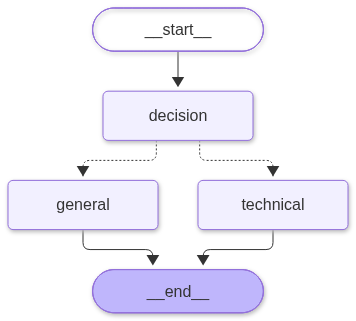

In [7]:
from IPython.display import Image

Image(graph.get_graph().draw_mermaid_png())


In [5]:
#  Run
while True:
    question = input("\nAsk a question (or exit): ")

    if question.lower() in ["exit", "quit"]:
        break
    
    print(question)
    result = graph.invoke({"question": question})

    print("\nAnswer:", result["answer"])

what are llms?

Answer: **LLMs = Large Language Models**

A Large Language Model is a deep neural network trained on massive amounts of text data to model the statistical distribution of language, and then use that model to predict, generate, and understand natural language.

Technically:

**1. Architecture**
Almost all modern LLMs are based on the Transformer architecture, introduced in "Attention Is All You Need" 2017. The core components are:
* **Self-attention mechanism:** Allows the model to weigh the importance of different tokens in a sequence relative to each other, enabling long-range dependencies.
* **Stacked encoder-decoder or decoder-only layers:** GPT-style models are decoder-only. Each layer consists of multi-head self-attention + feed-forward network with LayerNorm and residual connections.
* **Tokenization:** Input text is split into sub-word tokens via BPE or SentencePiece vocabularies, typically 32k-200k tokens.

**2. Training**
* **Pre-training:** Unsupervised next-t